# LensCent Inquiry Studio
An Arabic–English photography inquiry assistant. This notebook traces one workflow from customer messages to a reviewable reply and a held-out evaluation.

## 1 · Project environment
The setup cell locates the project files and checks the Python dependencies. A standalone Colab session accepts the project ZIP.

In [1]:
from pathlib import Path
from importlib import metadata, util
import os, sys, subprocess, tempfile, zipfile

root = Path.cwd()
if not (root / "pipeline.py").is_file():
    if util.find_spec("google") is None or util.find_spec("google.colab") is None:
        raise FileNotFoundError("The notebook requires the extracted project directory.")
    from google.colab import files
    print("Project archive (.zip)")
    uploaded = files.upload()
    archive = next((Path(name) for name in uploaded if name.lower().endswith(".zip")), None)
    if archive is None:
        raise ValueError("A project ZIP archive is required.")
    target = Path(tempfile.mkdtemp(prefix="lenscent_"))
    with zipfile.ZipFile(archive) as bundle:
        if any(not (target / item.filename).resolve().is_relative_to(target) for item in bundle.infolist()):
            raise ValueError("Invalid path inside the project archive.")
        bundle.extractall(target)
    root = next(target.rglob("pipeline.py")).parent
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
try:
    ready = metadata.version("scikit-learn") == "1.8.0" and all(util.find_spec(p) for p in ["pandas","numpy","matplotlib"])
except metadata.PackageNotFoundError:
    ready = False
if not ready:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"])
print("LensCent project files are ready.")

LensCent project files are ready.


## 2 · Text preparation
A fictional booking inquiry illustrates contact masking and Arabic normalization. Expressive Arabic letter runs of three or more become one letter, while ordinary pairs remain intact. The class counts describe the labeled dataset.

In [2]:
import pandas as pd
from IPython.display import display, Image
from pipeline import LABELS, mask, clean, read_data, split_customers

data, faq = read_data()
example = "أَبغى تصوير تخرّج، جوالي ٠٥٠٠٠٠٠٠٠٠ وبريدي demo@example.test"
display(pd.DataFrame({"المرحلة":["الأصل","بعد الحجب","مدخل النموذج"],
                      "النص":[example, mask(example), clean(example)]}))
display(data.groupby("topic").size().rename("عدد الرسائل").to_frame())
print(len(data), "رسالة /", data.customer_id.nunique(), "عميل افتراضي")
repeated_examples = ["غيرررروا موعد الحجززززز!", "أبييي أحجززز تصويررر", "الله يسلمك"]
display(pd.DataFrame({"Original": repeated_examples,
                      "Normalized": [clean(text) for text in repeated_examples]}))


204 رسالة / 102 عميل افتراضي


,المرحلة,النص
0,الأصل,أَبغى تصوير تخرّج، جوالي ٠٥٠٠٠٠٠٠٠٠ وبريدي dem...
1,بعد الحجب,أَبغى تصوير تخرّج، جوالي [PHONE] وبريدي [EMAIL]
2,مدخل النموذج,ابغي تصوير تخرج جوالي وبريدي


,عدد الرسائل
topic,
edit_request,39
gallery_access,43
outside,36
package_pricing,44
session_booking,42


,Original,Normalized
0,غيرررروا موعد الحجززززز!,غيروا موعد الحجز
1,أبييي أحجززز تصويررر,ابي احجز تصوير
2,الله يسلمك,الله يسلمك


## 3 · Customer split
Both messages from each simulated customer stay in the same partition. Validation sets the clarification threshold.

In [3]:
train_set, validation, test = split_customers(data)
parts = {"training":train_set, "validation":validation, "test":test}
customer_sets = [set(x.customer_id) for x in parts.values()]
assert sum(map(len, customer_sets)) == len(set.union(*customer_sets))
display(pd.DataFrame([{"part":name,"messages":len(x),"customers":x.customer_id.nunique()}
                      for name,x in parts.items()]))
print("Shared customers = 0")

Shared customers = 0


,part,messages,customers
0,training,120,60
1,validation,32,16
2,test,52,26


## 4 · Intent and FAQ ranking
A character-level linear SVM predicts the intent. A Ridge model approximates cached multilingual similarity scores for the reply library.

In [4]:
from train import train
metrics = train()
predictions = pd.read_csv("outputs/test_predictions.csv", keep_default_na=False)
display(predictions[["masked_text","topic","prediction","route","faq_id","correct"]].head(10))

Customers (train / validation / test): [{'messages': 120, 'customers': 60}, {'messages': 32, 'customers': 16}, {'messages': 52, 'customers': 26}]
Accuracy 0.808 | Macro-F1 0.806 | 4426 features
Retrieval: {'n': 24, 'student': {'top1': 0.625, 'recall3': 0.9166666666666666, 'mrr3': 0.7638888888888888}, 'teacher': {'top1': 0.9583333333333334, 'recall3': 0.9583333333333334, 'mrr3': 0.9583333333333334}}


,masked_text,topic,prediction,route,faq_id,correct
0,بكم تصوير عشرين قطعة للمتجر بخلفية موحّدة؟,package_pricing,package_pricing,answer,P01,True
1,ياليت توحدون الخلفية البيضاء في صور المنتجات.,edit_request,package_pricing,answer,P01,False
2,لون القهوة طالع غامق، ممكن تفتحونه شوي؟,edit_request,edit_request,answer,E01,True
3,كيف أحمّل الألبوم كامل مرة وحدة؟,gallery_access,gallery_access,clarify_faq,,True
4,وش الأوقات المتوفرة عندكم لجلسة تصوير مولود؟,session_booking,session_booking,answer,B01,True
5,أحتاج رابط جديد للمعرض عشان أنزل صور المولود.,gallery_access,gallery_access,clarify_faq,,True
6,كيف أغيّر وقت جلستي من العصر للمغرب؟,session_booking,session_booking,clarify_topic,,True
7,كيف أشارك رابط الألبوم مع أمي؟,gallery_access,gallery_access,answer,G01,True
8,أبي أنقل الحجز ليوم ثاني، يناسبكم الأحد؟,session_booking,outside,clarify_topic,,False
9,للحين ما وصلني رابط المعرض وين ألقاه؟,gallery_access,gallery_access,answer,G01,True


## 5 · Evaluation
Per-class F1 and the confusion matrix summarize classification on held-out customers. The error table contains individual predictions. FAQ retrieval uses a separate set of 24 questions.

95% customer-bootstrap accuracy interval: [0.6923, 0.9038]


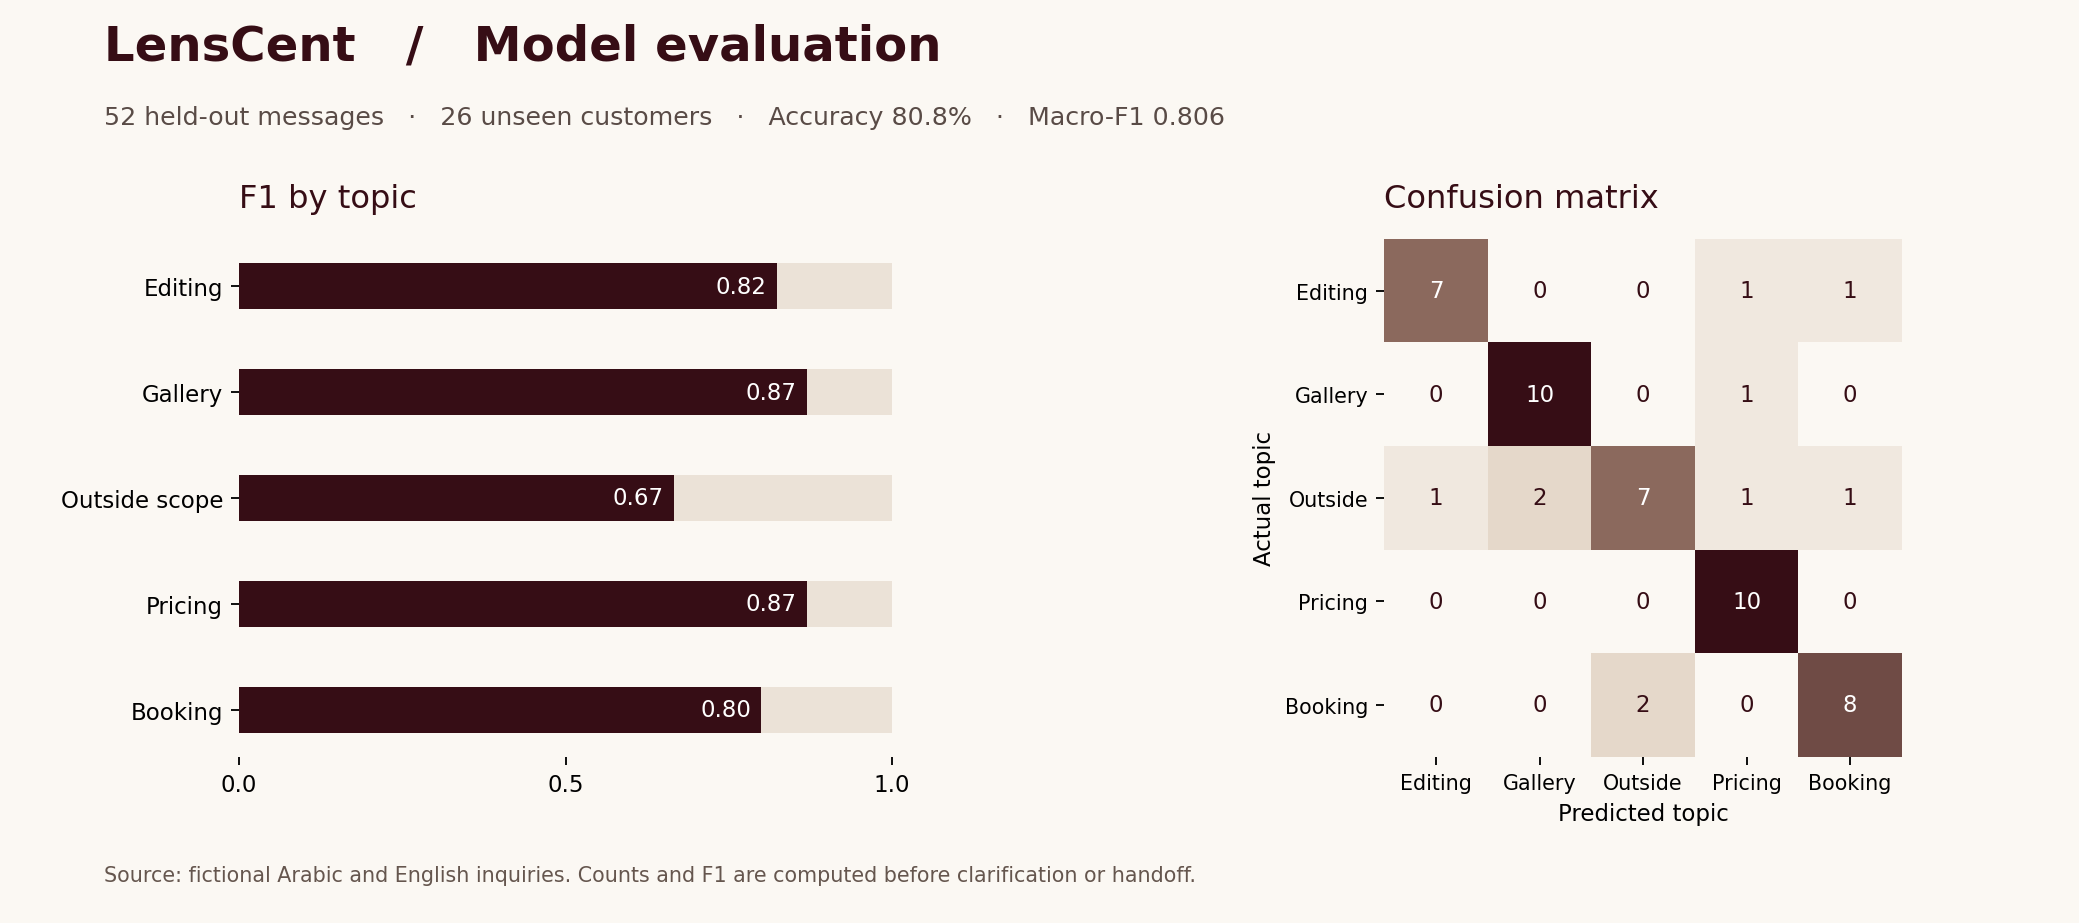

,masked_text,topic,prediction
1,ياليت توحدون الخلفية البيضاء في صور المنتجات.,edit_request,package_pricing
8,أبي أنقل الحجز ليوم ثاني، يناسبكم الأحد؟,session_booking,outside
11,أبي أحجز فوتوبوث للحفل، فيه مواعيد؟,session_booking,outside
15,عندكم جدول مباريات الأسبوع؟,outside,session_booking
40,Please brighten the group portrait a little,edit_request,session_booking
42,How do I renew my passport?,outside,gallery_access
46,How do I pay a parking fine?,outside,gallery_access
47,Can you recommend a pizza place?,outside,edit_request
48,What's the weather in Riyadh tomorrow?,outside,package_pricing
51,Can you help me save high-resolution photos?,gallery_access,package_pricing


,macro-F1
Word SVM,0.743
Character SVM,0.806
Fine-tuned CAMeLBERT,0.810


,top1,recall3,mrr3
teacher,0.958,0.958,0.958
student,0.625,0.917,0.764


In [5]:
from plots import plot_evaluation
display(Image(filename=str(plot_evaluation()), width=900))
display(predictions.loc[~predictions.correct, ["masked_text","topic","prediction"]])
print("95% customer-bootstrap accuracy interval:", metrics["accuracy_ci"])
if "camelbert_f1" in metrics:
    display(pd.Series({"Word SVM":metrics["word_f1"],"Character SVM":metrics["macro_f1"],
                       "Fine-tuned CAMeLBERT":metrics["camelbert_f1"]}, name="macro-F1").round(3).to_frame())
display(pd.DataFrame({k:metrics["retrieval"][k] for k in ["teacher","student"]}).T.round(3))

## 6 · Browser demo
The exported HTML contains the interface and model weights. Colab displays the web version in an embedded frame.

In [6]:
from export_html import export_demo
from IPython.display import FileLink
export_demo()
try:
    from google.colab import output
except ImportError:
    display(FileLink("LensCent_Demo.html", result_html_prefix="فتح نسخة العرض · "))
else:
    import threading
    from functools import partial
    from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
    if "lens_server" not in globals():
        handler = partial(SimpleHTTPRequestHandler, directory=str(root / "web"))
        lens_server = ThreadingHTTPServer(("127.0.0.1", 0), handler)
        threading.Thread(target=lens_server.serve_forever, daemon=True).start()
    output.serve_kernel_port_as_iframe(lens_server.server_port, height=800)

/workspace/scratch/b9b5f8fafafc/elongation-project/LensCent_Demo.html

## 7 · Subword alignment and attention
The table maps each token to its original word. Continuation pieces and special tokens receive −100. The figure shows the first attention head in the first CAMeLBERT layer.

,token_index,token,word_id,aligned_label
0,0,[CLS],NaN,-100
1,1,طلبت,0.0,O
2,2,رغ,1.0,B-PER
3,3,##د,1.0,-100
4,4,تصوير,2.0,B-SERVICE
5,5,بالرياض,3.0,B-LOC
6,6,[SEP],NaN,-100


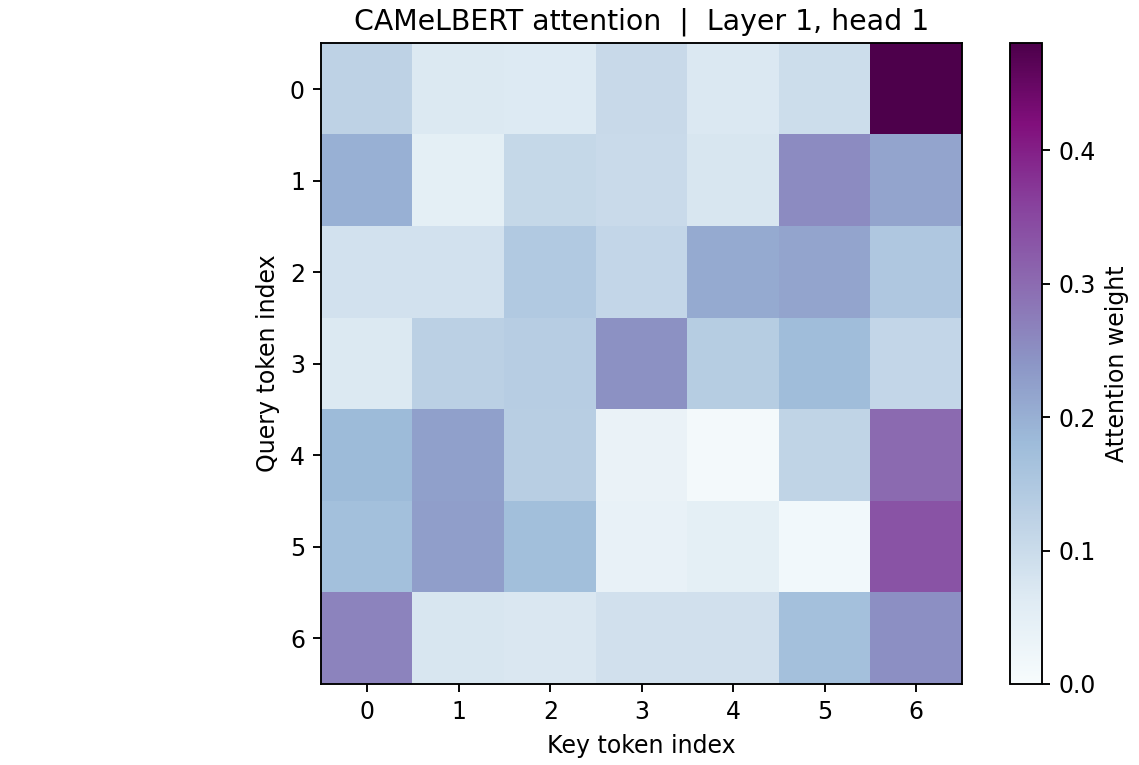

In [7]:
alignment = pd.read_csv("outputs/token_alignment.csv")
display(alignment)
display(Image(filename="outputs/attention.png", width=570))

## 8 · Optional transformer experiments
The three flags control semantic search, attention inspection and CAMeLBERT fine-tuning. All default to False. The first run of an enabled experiment downloads the relevant model.

In [8]:
RUN_SEARCH = False
RUN_ATTENTION = False
RUN_FINETUNE = False
query = "Where can I find the access code to my gallery?"

if any((RUN_SEARCH, RUN_ATTENTION, RUN_FINETUNE)):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-neural.txt"])
if RUN_SEARCH:
    from prepare_teacher import FAQSearch
    if "full_search" not in globals():
        full_search = FAQSearch(faq)
    scores = full_search.scores([query])[0]
    display(pd.DataFrame({"FAQ":[item["ar"] for item in faq], "cosine":scores})
            .sort_values("cosine", ascending=False).head(3))
if RUN_ATTENTION:
    from transformer_lab import inspect_tokens
    display(inspect_tokens())
    display(Image(filename="outputs/attention.png", width=570))
if RUN_FINETUNE:
    from transformer_lab import finetune
    display(finetune())
    metrics = train()
    export_demo()
if not any((RUN_SEARCH, RUN_ATTENTION, RUN_FINETUNE)):
    print("Optional experiments are disabled. Recorded results appear above.")

Optional experiments are disabled. Recorded results appear above.


The **outputs/** directory contains the figures and predictions. **data/** holds the labeled messages, FAQ entries and retrieval questions.